# Лабораторная работа №5. Градиентный бустинг

## Цель работы

В этой работе я исследую градиентный бустинг для покупки страховки
и цены ноутбука. Сравниваю модели sklearn и реализации на NumPy
с исходными настройками и после подбора параметров.

## Данные и метрики

Используются те же наборы, признаки и разбиения, что в ЛР1–4.

- [Travel Insurance Prediction Data](https://www.kaggle.com/datasets/tejashvi14/travel-insurance-prediction-data): цель TravelInsurance. Основная метрика — macro-F1, дополнительно Accuracy, ROC-AUC и матрица ошибок. Macro-F1 учитывает качество обоих классов при разном числе покупателей и непокупателей.
- [Laptop Prices](https://www.kaggle.com/datasets/owm4096/laptop-prices): цель Price_euros. Основная метрика — MAE в евро, дополнительно RMSE и R². MAE показывает среднюю абсолютную ошибку, RMSE сильнее реагирует на крупные промахи.

Прогноз покупки может помочь выбрать клиентов для предложения полиса.
Оценка цены позволяет сопоставлять ноутбуки по характеристикам.
Цены относятся к исходному набору данных.

Сравнение всех пяти алгоритмов находится в [итоговом ноутбуке](lab6_summary.ipynb).

## Проверка окружения

Сначала вывожу версии библиотек и задаю random_state=42.

In [1]:
# Проверяем окружение для градиентного бустинга.
import sys
import json
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    StratifiedGroupKFold, GroupShuffleSplit, GroupKFold, cross_validate,
)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.dummy import DummyClassifier, DummyRegressor

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.13.18
NumPy: 2.4.6
pandas: 2.2.3
scikit-learn: 1.6.1


## Загрузка данных

Используются исходные CSV из ЛР1. Перед чтением проверяются их контрольные
суммы: файлы и порядок строк должны совпадать с первым исследованием.

In [2]:
# Загружаем два исходных CSV.
from google.colab import files

uploaded = files.upload()

Saving laptop_prices.csv to laptop_prices.csv
Saving TravelInsurancePrediction.csv to TravelInsurancePrediction.csv


In [3]:
# Проверяем версии исходных файлов и читаем таблицы.
source_hashes = {
    "TravelInsurancePrediction.csv": "26c79f34d14138771983be3dc2dbf019c6e8b20d78db9109261149dec63da426",
    "laptop_prices.csv": "3638d6dc2c50b89263c99b364173a1f773e0b1fb0b83aa080749e95b7a77da8d"
}

for filename, expected_hash in source_hashes.items():
    actual_hash = hashlib.sha256(Path(filename).read_bytes()).hexdigest()
    assert actual_hash == expected_hash, (
        f"Файл {filename} отличается от использованного в ЛР1."
    )

travel = pd.read_csv("TravelInsurancePrediction.csv")
laptops = pd.read_csv("laptop_prices.csv")

# Проверяем и исключаем служебный индекс.
assert np.array_equal(travel["Unnamed: 0"].to_numpy(), np.arange(len(travel)))
travel = travel.drop(columns="Unnamed: 0")

print("Страховка:", travel.shape)
print("Ноутбуки:", laptops.shape)
print("Пропуски:", travel.isna().sum().sum(), laptops.isna().sum().sum())

Страховка: (1987, 9)
Ноутбуки: (1275, 23)
Пропуски: 0 0


## Разбиения из ЛР1

Строки с одинаковыми входными признаками объединены в группы. Одна группа
целиком попадает в train или test; это позволяет проверить прогнозы на
новых сочетаниях характеристик. Целевая переменная в группы не входит.

Для страховки используется первая часть StratifiedGroupKFold из пяти,
для ноутбуков — GroupShuffleSplit с 20% групп в тесте. Настройки и seed
сохранены из ЛР1. Результат разделения и три части CV проверяются по
контрольным суммам распределения строк. Ноутбук запускается отдельно от ЛР1.

Набор входных столбцов также сохранён. Для ноутбуков исключены Product,
CPU_model и GPU_model, чтобы ограничить число редких категорий.

In [4]:
# Восстанавливаем признаки и разбиения по протоколу ЛР1.
classification_features = [
    "Age",
    "Employment Type",
    "GraduateOrNot",
    "AnnualIncome",
    "FamilyMembers",
    "ChronicDiseases",
    "FrequentFlyer",
    "EverTravelledAbroad"
]
regression_features = [
    "Company",
    "TypeName",
    "Inches",
    "Ram",
    "OS",
    "Weight",
    "Screen",
    "ScreenW",
    "ScreenH",
    "Touchscreen",
    "IPSpanel",
    "RetinaDisplay",
    "CPU_company",
    "CPU_freq",
    "PrimaryStorage",
    "SecondaryStorage",
    "PrimaryStorageType",
    "SecondaryStorageType",
    "GPU_company"
]
expected_protocol = {
    "travel": {
        "test_mask_sha256": "26baec97124eb0502e188b8451b25f110001b8c5d7c7ef7e0391b2982f09e97d",
        "cv_assignment_sha256": "96aebde84f18d8298cb2013035e3499b7c42e5103e5b95d8b337f7afb125d321"
    },
    "laptops": {
        "test_mask_sha256": "88fed4bc26da4cdd5bf8d6edb965a0e27322070907a2b50ab0017abc9cb97b3d",
        "cv_assignment_sha256": "68661b03ff5b016ab29e97c79596e6f67bedd74821bd782b3b9943f27edb7f45"
    }
}

X_cls = travel[classification_features].copy()
y_cls = travel["TravelInsurance"].copy()
X_reg = laptops[regression_features].copy()
y_reg = laptops["Price_euros"].copy()

groups_cls = pd.factorize(pd.MultiIndex.from_frame(X_cls))[0]
groups_reg = pd.factorize(pd.MultiIndex.from_frame(X_reg))[0]

split_cls = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE,
)
train_idx_cls, test_idx_cls = next(split_cls.split(X_cls, y_cls, groups_cls))
split_reg = GroupShuffleSplit(
    n_splits=1, test_size=0.2, random_state=RANDOM_STATE,
)
train_idx_reg, test_idx_reg = next(split_reg.split(X_reg, y_reg, groups_reg))

X_train_cls, X_test_cls = X_cls.iloc[train_idx_cls].copy(), X_cls.iloc[test_idx_cls].copy()
y_train_cls, y_test_cls = y_cls.iloc[train_idx_cls].copy(), y_cls.iloc[test_idx_cls].copy()
X_train_reg, X_test_reg = X_reg.iloc[train_idx_reg].copy(), X_reg.iloc[test_idx_reg].copy()
y_train_reg, y_test_reg = y_reg.iloc[train_idx_reg].copy(), y_reg.iloc[test_idx_reg].copy()
groups_train_cls = groups_cls[train_idx_cls]
groups_train_reg = groups_reg[train_idx_reg]

cv_cls = StratifiedGroupKFold(
    n_splits=3, shuffle=True, random_state=RANDOM_STATE,
)
cv_reg = GroupKFold(n_splits=3)
cv_folds_cls = list(cv_cls.split(X_train_cls, y_train_cls, groups_train_cls))
cv_folds_reg = list(cv_reg.split(X_train_reg, y_train_reg, groups_train_reg))

def text_hash(text):
    return hashlib.sha256(text.encode("utf-8")).hexdigest()

# Проверяем номера строк test и распределение train по частям CV.
for name, X, groups, train_idx, test_idx, folds in [
    ("travel", X_cls, groups_cls, train_idx_cls, test_idx_cls, cv_folds_cls),
    ("laptops", X_reg, groups_reg, train_idx_reg, test_idx_reg, cv_folds_reg),
]:
    mask = np.zeros(len(X), dtype=int)
    mask[test_idx] = 1
    assert text_hash("".join(map(str, mask))) == expected_protocol[name]["test_mask_sha256"]
    assert not (set(groups[train_idx]) & set(groups[test_idx]))

    codes = np.full(len(X), "-", dtype="<U1")
    for fold_number, (fit_positions, valid_positions) in enumerate(folds):
        assert not (
            set(groups[train_idx[fit_positions]])
            & set(groups[train_idx[valid_positions]])
        )
        codes[train_idx[valid_positions]] = str(fold_number)
    assert text_hash("".join(codes)) == expected_protocol[name]["cv_assignment_sha256"]
    print(f"{name}: train={len(train_idx)}, test={len(test_idx)}; разбиения совпали с ЛР1")

travel: train=1543, test=444; разбиения совпали с ЛР1
laptops: train=1009, test=266; разбиения совпали с ЛР1


## Исходные библиотечные модели

Градиентный бустинг последовательно добавляет деревья к текущему
прогнозу. Каждое следующее дерево приближает отрицательный градиент
функции потерь. Вклад нового дерева умножается на learning_rate.

Используются GradientBoostingClassifier с log_loss и
GradientBoostingRegressor с squared_error. Исходные настройки:
100 деревьев, learning_rate=0.1, max_depth=3,
min_samples_leaf=1, subsample=1.0. Случайное выделение внутренней
валидации и ранняя остановка не включены.

Числовые признаки передаются без масштабирования. Категории
кодируются OneHotEncoder внутри Pipeline: кодировщик обучается
на обучающей части каждого фолда. Неизвестные категории кодируются
нулевыми значениями в соответствующем блоке.

Модели и Dummy оцениваются на трёх зафиксированных групповых частях CV.
Тестовая выборка на этом этапе не используется.

In [5]:
# Оцениваем исходные модели бустинга и Dummy на фиксированных частях CV.
def make_boosting_preprocessor(X):
    numeric_columns = X.select_dtypes(include="number").columns.tolist()
    categorical_columns = [c for c in X.columns if c not in numeric_columns]
    return ColumnTransformer([
        ("numeric", "passthrough", numeric_columns),
        ("categorical", OneHotEncoder(
            handle_unknown="ignore", sparse_output=False,
        ), categorical_columns),
    ])


def make_boosting_pipeline(X, model):
    return Pipeline([
        ("preprocessor", make_boosting_preprocessor(X)),
        ("model", model),
    ])


def evaluate_boosting_models(models, X, y, folds, scoring):
    rows = []
    for name, model in models.items():
        scores = cross_validate(
            make_boosting_pipeline(X, model), X, y, cv=folds,
            scoring=scoring, n_jobs=-1, error_score="raise",
        )
        row = {"model": name}
        for metric, scorer in scoring.items():
            values = scores[f"test_{metric}"]
            if scorer.startswith("neg_"):
                values = -values
            row[f"{metric}_mean"] = values.mean()
            row[f"{metric}_std"] = values.std(ddof=1)
        rows.append(row)
    return pd.DataFrame(rows)


scoring_cls = {"macro_f1": "f1_macro", "accuracy": "accuracy", "roc_auc": "roc_auc"}
scoring_reg = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2",
}

baseline_cv_cls = evaluate_boosting_models(
    {
        "Dummy": DummyClassifier(strategy="most_frequent"),
        "GradientBoosting baseline": GradientBoostingClassifier(
            n_estimators=100, learning_rate=0.1, max_depth=3,
            loss="log_loss", random_state=RANDOM_STATE,
        ),
    },
    X_train_cls, y_train_cls, cv_folds_cls, scoring_cls,
)
baseline_cv_reg = evaluate_boosting_models(
    {
        "Dummy": DummyRegressor(strategy="median"),
        "GradientBoosting baseline": GradientBoostingRegressor(
            n_estimators=100, learning_rate=0.1, max_depth=3,
            loss="squared_error", random_state=RANDOM_STATE,
        ),
    },
    X_train_reg, y_train_reg, cv_folds_reg, scoring_reg,
)

results_dir = Path("/content/results")
results_dir.mkdir(parents=True, exist_ok=True)
baseline_cv_cls.to_csv(results_dir / "lab5_baseline_cv_classification.csv", index=False)
baseline_cv_reg.to_csv(results_dir / "lab5_baseline_cv_regression.csv", index=False)

print("Классификация: исходные модели на CV")
display(baseline_cv_cls.round(4))
print("Регрессия: исходные модели на CV")
display(baseline_cv_reg.round(4))

Классификация: исходные модели на CV


,model,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std,roc_auc_mean,roc_auc_std
0,Dummy,0.3893,0.0087,0.6378,0.0235,0.5000,0.000
1,GradientBoosting baseline,0.7922,0.0288,0.8254,0.0152,0.8248,0.037


Регрессия: исходные модели на CV


,model,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std
0,Dummy,528.9241,8.4828,722.8491,14.0135,-0.0517,0.0085
1,GradientBoosting baseline,202.0231,9.4434,295.6588,25.6478,0.8221,0.0391


## Подбор параметров бустинга

Исходные модели получили на CV macro-F1 = 0.7922 для страховки
и MAE = 202.02 евро для цены ноутбука. Обе лучше Dummy.

Проверяется гипотеза о совместном влиянии шага и числа деревьев:
при меньшем learning_rate может потребоваться больше итераций.
Уменьшение глубины и увеличение минимального размера листа
могут снизить переобучение, но также могут привести к недообучению.

В каждой задаче проверяются 16 сочетаний: n_estimators — 100 или 200,
learning_rate — 0.05 или 0.1, max_depth — 2 или 3,
min_samples_leaf — 1 или 10. Сетка включает исходный вариант.
Остальные параметры и признаки не меняются.

Выбор производится по macro-F1 и MAE на тех же трёх групповых
частях CV. Тест оставляю для итоговой оценки. Дополнительно сравниваю
результаты на обучающих и проверочных частях CV.

In [6]:
"""Подбираем число деревьев, шаг и сложность бустинга на фиксированной групповой CV."""

from sklearn.model_selection import GridSearchCV


# Глубина ограничивает число последовательных условий, размер листа —
# минимальное число обучающих наблюдений, по которым делается прогноз.
search_cls = GridSearchCV(
    estimator=make_boosting_pipeline(
        X_train_cls, GradientBoostingClassifier(loss="log_loss", random_state=RANDOM_STATE),
    ),
    param_grid={
        "model__n_estimators": [100, 200],
        "model__learning_rate": [0.05, 0.1],
        "model__max_depth": [2, 3],
        "model__min_samples_leaf": [1, 10],
    },
    scoring=scoring_cls,
    refit="macro_f1",
    cv=cv_folds_cls,
    return_train_score=True,
    n_jobs=-1,
    error_score="raise",
    verbose=1,
)
search_reg = GridSearchCV(
    estimator=make_boosting_pipeline(
        X_train_reg, GradientBoostingRegressor(loss="squared_error", random_state=RANDOM_STATE),
    ),
    param_grid={
        "model__n_estimators": [100, 200],
        "model__learning_rate": [0.05, 0.1],
        "model__max_depth": [2, 3],
        "model__min_samples_leaf": [1, 10],
    },
    scoring=scoring_reg,
    refit="mae",
    cv=cv_folds_reg,
    return_train_score=True,
    n_jobs=-1,
    error_score="raise",
    verbose=1,
)

search_cls.fit(X_train_cls, y_train_cls)
search_reg.fit(X_train_reg, y_train_reg)


def selected_cv_row(search, scoring, name, n_folds):
    # Считаем разброс с ddof=1, как в таблице исходных моделей.
    i = search.best_index_
    row = {"model": name}
    for metric, scorer in scoring.items():
        values = np.array([
            search.cv_results_[f"split{fold}_test_{metric}"][i]
            for fold in range(n_folds)
        ])
        if scorer.startswith("neg_"):
            values = -values
        row[f"{metric}_mean"] = values.mean()
        row[f"{metric}_std"] = values.std(ddof=1)
    return row


boosting_search_cv_cls = pd.concat([
    baseline_cv_cls,
    pd.DataFrame([selected_cv_row(
        search_cls, scoring_cls, "GradientBoosting tuned", len(cv_folds_cls),
    )]),
], ignore_index=True)
boosting_search_cv_reg = pd.concat([
    baseline_cv_reg,
    pd.DataFrame([selected_cv_row(
        search_reg, scoring_reg, "GradientBoosting tuned", len(cv_folds_reg),
    )]),
], ignore_index=True)

print("Классификация: выбранные параметры", search_cls.best_params_)
display(boosting_search_cv_cls.round(4))
print("Регрессия: выбранные параметры", search_reg.best_params_)
display(boosting_search_cv_reg.round(4))

# Сравниваем качество на обучающих и проверочных частях каждого CV-фолда.
# Полный train здесь не используется как проверочная выборка.
complexity_rows = []
for task, search, metric, sign in [
    ("classification", search_cls, "macro_f1", 1),
    ("regression", search_reg, "mae", -1),
]:
    for variant, parameters in [("baseline", None), ("tuned", search.best_params_)]:
        if parameters is None:
            candidates = [
                i for i, p in enumerate(search.cv_results_["params"])
                if p["model__n_estimators"] == 100
                and p["model__learning_rate"] == 0.1
                and p["model__max_depth"] == 3
                and p["model__min_samples_leaf"] == 1
            ]
            assert len(candidates) == 1
            i = candidates[0]
        else:
            i = search.best_index_
        complexity_rows.append({
            "task": task,
            "variant": variant,
            "metric": metric,
            "train_mean": sign * search.cv_results_[f"mean_train_{metric}"][i],
            "validation_mean": sign * search.cv_results_[f"mean_test_{metric}"][i],
        })
complexity_comparison = pd.DataFrame(complexity_rows)
print("Обучающие и проверочные части CV: оценка переобучения")
display(complexity_comparison.round(4))

boosting_search_cv_cls.to_csv(results_dir / "lab5_search_cv_classification.csv", index=False)
boosting_search_cv_reg.to_csv(results_dir / "lab5_search_cv_regression.csv", index=False)
complexity_comparison.to_csv(results_dir / "lab5_complexity_comparison.csv", index=False)
pd.DataFrame(search_cls.cv_results_).to_csv(
    results_dir / "lab5_grid_classification.csv", index=False,
)
pd.DataFrame(search_reg.cv_results_).to_csv(
    results_dir / "lab5_grid_regression.csv", index=False,
)
(results_dir / "lab5_selected_parameters.json").write_text(
    json.dumps({
        "classification": search_cls.best_params_,
        "regression": search_reg.best_params_,
    }, ensure_ascii=False, indent=2), encoding="utf-8",
)

Fitting 3 folds for each of 16 candidates, totalling 48 fits
Fitting 3 folds for each of 16 candidates, totalling 48 fits
Классификация: выбранные параметры {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}


,model,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std,roc_auc_mean,roc_auc_std
0,Dummy,0.3893,0.0087,0.6378,0.0235,0.5000,0.0000
1,GradientBoosting baseline,0.7922,0.0288,0.8254,0.0152,0.8248,0.0370
2,GradientBoosting tuned,0.8041,0.0343,0.8375,0.0225,0.8075,0.0581


Регрессия: выбранные параметры {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}


,model,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std
0,Dummy,528.9241,8.4828,722.8491,14.0135,-0.0517,0.0085
1,GradientBoosting baseline,202.0231,9.4434,295.6588,25.6478,0.8221,0.0391
2,GradientBoosting tuned,195.3908,14.0494,287.7311,32.7536,0.8306,0.0456


Обучающие и проверочные части CV: оценка переобучения


,task,variant,metric,train_mean,validation_mean
0,classification,baseline,macro_f1,0.8292,0.7922
1,classification,tuned,macro_f1,0.8093,0.8041
2,regression,baseline,mae,149.7839,202.0231
3,regression,tuned,mae,121.3060,195.3908


302

### Результаты подбора

Для классификации выбраны 100 деревьев, learning_rate=0.1,
max_depth=2 и min_samples_leaf=1. Macro-F1 на CV вырос
с 0.7922 до 0.8041, а разрыв с обучающими частями уменьшился.
При этом ROC-AUC снизился с 0.8248 до 0.8075. Выбор произведён
по основной метрике macro-F1, улучшение всех метрик не получено.

Для регрессии выбраны 200 деревьев, learning_rate=0.1,
max_depth=3 и min_samples_leaf=1. MAE на CV снизилась
с 202.02 до 195.39 евро. Ошибка на обучающих частях уменьшилась
с 149.78 до 121.31 евро, разрыв с CV вырос. Это не позволяет
утверждать, что настройка уменьшила переобучение регрессора.

Шаг 0.05 и увеличение размера листа не вошли в выбранные модели.
Окончательное качество будет оценено на отложенном тесте.

## Собственный градиентный бустинг

В регрессии начальный прогноз равен среднему y на train.
На каждом шаге дерево обучается на остатках y-F(X), затем
его прогноз добавляется с множителем learning_rate.

В бинарной классификации начальный логит равен log(p/(1-p)),
где p — доля положительного класса в обучающей части.
Вероятность получается сигмоидой логита. Дерево обучается
на отрицательном градиенте y-p, после чего значения листьев
уточняются шагом Ньютона: sum(y-p)/sum(p*(1-p)).
Новый прогноз добавляется к логиту с множителем learning_rate.
Для вырожденного знаменателя обновление листа принимается равным нулю.

Внутренние регрессионные деревья также реализованы на NumPy.
Их пороги выбираются по уменьшению суммы квадратов ошибок.
Поддерживаются используемые в работе глубина, размер листа,
число деревьев и шаг обучения; subsample=1.0 и ранняя остановка
не меняются. Реализация классификации рассчитана на два класса.
Готовые модели sklearn внутри собственного алгоритма не вызываются.

При равном улучшении нескольких разделений порядок признаков
может приводить к отличиям от sklearn. Полное совпадение
на реальных данных не предполагается. Формулировка алгоритма:
[документация scikit-learn](https://scikit-learn.org/1.6/modules/ensemble.html#mathematical-formulation).

In [7]:
"""Градиентный бустинг на NumPy: squared_error и бинарная log_loss."""

from numbers import Integral, Real

import numpy as np
from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin
from sklearn.utils import check_random_state
from sklearn.utils.multiclass import check_classification_targets
from sklearn.utils.validation import check_X_y, check_array, check_is_fitted


def _boost_sigmoid(values):
    result = np.empty_like(values, dtype=float)
    positive = values >= 0
    result[positive] = 1.0 / (1.0 + np.exp(-values[positive]))
    exp_values = np.exp(values[~positive])
    result[~positive] = exp_values / (1.0 + exp_values)
    return result


class _BoostingTree:
    """Регрессионное CART-дерево для приближения отрицательного градиента."""

    def __init__(self, max_depth, min_samples_leaf, random_state):
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.random_state = random_state

    def fit(self, X, y):
        rng = np.random.RandomState(self.random_state)
        self.n_features_in_ = X.shape[1]
        self.depth_, self.n_leaves_ = 0, 0
        importance = np.zeros(X.shape[1])

        def grow(indices, depth):
            target = y[indices]
            n = len(indices)
            mean = float(target.mean())
            node = {"feature": None, "value": mean, "n_samples": n}
            self.depth_ = max(self.depth_, depth)
            if (depth >= self.max_depth or n < 2 * self.min_samples_leaf
                    or np.mean((target - mean) ** 2) <= 1e-15):
                self.n_leaves_ += 1
                return node
            # Рассматриваются все признаки; перестановка определяет выбор
            # при равном уменьшении ошибки у нескольких разделений.
            features = rng.permutation(X.shape[1])
            matrix = X[np.ix_(indices, features)]
            order = np.argsort(matrix, axis=0, kind="stable")
            sorted_values = np.take_along_axis(matrix, order, axis=0)
            positions = np.arange(1, n)[:, None]
            valid = ((sorted_values[:-1] < sorted_values[1:])
                     & (positions >= self.min_samples_leaf)
                     & (n - positions >= self.min_samples_leaf))
            if not valid.any():
                self.n_leaves_ += 1
                return node
            centered = (target - mean)[order]
            sums = np.cumsum(centered, axis=0)[:-1]
            remaining = centered.sum(axis=0) - sums
            gains = (sums ** 2 / positions + remaining ** 2 / (n - positions)) / n
            gains = np.where(valid, gains, -np.inf)
            column, cut_index = np.unravel_index(np.argmax(gains.T), gains.T.shape)
            gain = float(gains[cut_index, column])
            threshold = (sorted_values[cut_index, column] / 2.0
                         + sorted_values[cut_index + 1, column] / 2.0)
            if threshold >= sorted_values[cut_index + 1, column]:
                threshold = sorted_values[cut_index, column]
            ordered = indices[order[:, column]]
            feature = int(features[column])
            importance[feature] += n * max(0.0, gain)
            node.update(feature=feature, threshold=float(threshold),
                        left=grow(ordered[:cut_index + 1], depth + 1),
                        right=grow(ordered[cut_index + 1:], depth + 1))
            return node

        self.tree_ = grow(np.arange(len(y)), 0)
        self.impurity_decreases_ = importance
        total = importance.sum()
        self.feature_importances_ = importance / total if total > 0 else importance
        return self

    def predict(self, X):
        result = np.empty(len(X))

        def descend(node, indices):
            if len(indices) == 0:
                return
            if node["feature"] is None:
                result[indices] = node["value"]
                return
            mask = X[indices, node["feature"]] <= node["threshold"]
            descend(node["left"], indices[mask])
            descend(node["right"], indices[~mask])

        descend(self.tree_, np.arange(len(X)))
        return result

    def update_log_loss_leaves(self, X, residual, probabilities):
        # Структура обучена на y-p. В листьях выполняется шаг Ньютона
        # для log_loss: sum(y-p) / sum(p*(1-p)).
        def update(node, indices):
            if node["feature"] is None:
                denominator = np.sum(probabilities[indices] * (1 - probabilities[indices]))
                node["value"] = (float(residual[indices].sum() / denominator)
                                 if denominator > 1e-12 else 0.0)
                return
            mask = X[indices, node["feature"]] <= node["threshold"]
            update(node["left"], indices[mask])
            update(node["right"], indices[~mask])

        update(self.tree_, np.arange(len(X)))

    def get_depth(self):
        return self.depth_

    def get_n_leaves(self):
        return self.n_leaves_


class _BoostingBase:
    def _fit_boosting(self, X, y, classification):
        X, y = check_X_y(X, y, dtype=np.float64, y_numeric=not classification)
        for name in ["n_estimators", "max_depth", "min_samples_leaf"]:
            value = getattr(self, name)
            if isinstance(value, bool) or not isinstance(value, Integral) or value < 1:
                raise ValueError(f"{name} должно быть положительным целым числом.")
        if (isinstance(self.learning_rate, bool) or not isinstance(self.learning_rate, Real)
                or not np.isfinite(self.learning_rate) or self.learning_rate <= 0):
            raise ValueError("learning_rate должно быть конечным и положительным.")
        self.n_features_in_ = X.shape[1]
        if classification:
            check_classification_targets(y)
            self.classes_, target = np.unique(y, return_inverse=True)
            self.n_classes_ = len(self.classes_)
            if self.n_classes_ != 2:
                raise ValueError("Реализована бинарная классификация с двумя классами.")
            target = target.astype(float)
            prior = target.mean()
            self.init_prediction_ = float(np.log(prior / (1 - prior)))
        else:
            target = y.astype(float)
            self.init_prediction_ = float(target.mean())
        raw = np.full(len(target), self.init_prediction_)
        rng = check_random_state(self.random_state)
        self.estimators_ = []
        history = []

        def loss():
            if classification:
                return float(np.mean(np.logaddexp(0, raw) - target * raw))
            return float(np.mean((target - raw) ** 2))

        history.append(loss())
        for _ in range(self.n_estimators):
            probabilities = _boost_sigmoid(raw) if classification else None
            residual = target - probabilities if classification else target - raw
            tree = _BoostingTree(
                self.max_depth, self.min_samples_leaf,
                int(rng.randint(np.iinfo(np.int32).max)),
            ).fit(X, residual)
            if classification:
                tree.update_log_loss_leaves(X, residual, probabilities)
            raw += self.learning_rate * tree.predict(X)
            self.estimators_.append(tree)
            history.append(loss())
        self.n_estimators_ = len(self.estimators_)
        self.loss_history_ = np.asarray(history)
        self.train_score_ = self.loss_history_[1:].copy()
        importance = np.sum([t.impurity_decreases_ for t in self.estimators_], axis=0)
        total = importance.sum()
        self.feature_importances_ = importance / total if total > 0 else importance
        return self

    def _prediction_input(self, X):
        check_is_fitted(self, ["estimators_", "init_prediction_", "n_features_in_"])
        X = check_array(X, dtype=np.float64)
        if X.shape[1] != self.n_features_in_:
            raise ValueError("Число признаков отличается от обучающей выборки.")
        return X

    def _raw_prediction(self, X):
        X = self._prediction_input(X)
        raw = np.full(len(X), self.init_prediction_)
        for tree in self.estimators_:
            raw += self.learning_rate * tree.predict(X)
        return raw

    def _staged_raw_prediction(self, X):
        X = self._prediction_input(X)
        raw = np.full(len(X), self.init_prediction_)
        for tree in self.estimators_:
            raw += self.learning_rate * tree.predict(X)
            yield raw.copy()


class MyGradientBoostingRegressor(RegressorMixin, _BoostingBase, BaseEstimator):
    """Бустинг с MSE: начальное среднее и деревья на остатках y-F(X)."""

    def __init__(self, n_estimators=100, learning_rate=0.1, max_depth=3,
                 min_samples_leaf=1, random_state=None):
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.random_state = random_state

    def fit(self, X, y):
        return self._fit_boosting(X, y, classification=False)

    def predict(self, X):
        return self._raw_prediction(X)

    def staged_predict(self, X):
        yield from self._staged_raw_prediction(X)


class MyGradientBoostingClassifier(ClassifierMixin, _BoostingBase, BaseEstimator):
    """Бинарный бустинг с log_loss и обновлением значений листьев Ньютона."""

    def __init__(self, n_estimators=100, learning_rate=0.1, max_depth=3,
                 min_samples_leaf=1, random_state=None):
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.random_state = random_state

    def fit(self, X, y):
        return self._fit_boosting(X, y, classification=True)

    def decision_function(self, X):
        return self._raw_prediction(X)

    def predict_proba(self, X):
        positive = _boost_sigmoid(self.decision_function(X))
        return np.column_stack([1 - positive, positive])

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]

    def staged_predict_proba(self, X):
        for raw in self._staged_raw_prediction(X):
            positive = _boost_sigmoid(raw)
            yield np.column_stack([1 - positive, positive])

### Проверка вычислений

Градиент log_loss проверяется конечными разностями. Первый шаг
регрессии и классификации сравнивается с ручным расчётом,
несколько шагов на простом одномерном примере — со sklearn.
Отдельно проверяются постоянные признаки, дисбаланс классов,
порог внутреннего дерева, последовательная сумма деревьев,
ограничения роста и воспроизводимость.

In [8]:
"""Проверяем градиенты, начальный прогноз и последовательные шаги бустинга."""

from numpy.testing import assert_allclose, assert_array_equal
from sklearn.base import clone

# Производная log_loss по логиту должна быть p-y.
raw_check = np.array([-2.0, 0.1, 3.0])
y_check = np.array([0.0, 1.0, 1.0])
epsilon = 1e-6
def individual_log_loss(raw):
    return np.logaddexp(0, raw) - y_check * raw
numerical_gradient = (
    individual_log_loss(raw_check + epsilon)
    - individual_log_loss(raw_check - epsilon)
) / (2 * epsilon)
assert_allclose(numerical_gradient, _boost_sigmoid(raw_check) - y_check, atol=1e-8)
assert_allclose(_boost_sigmoid(np.array([-1000.0, 0.0, 1000.0])), [0.0, 0.5, 1.0])

toy_X = np.arange(8, dtype=float).reshape(-1, 1)
queries = np.array([[-1.0], [2.0], [3.5], [4.0], [10.0]])
toy_reg = np.array([10.0] * 4 + [30.0] * 4)
toy_cls = np.array(["no"] * 4 + ["yes"] * 4)

# Начальный прогноз регрессии — 20; одно дерево предсказывает -10 или 10.
one_reg = MyGradientBoostingRegressor(
    n_estimators=1, learning_rate=0.1, max_depth=1, random_state=42,
).fit(toy_X, toy_reg)
assert_allclose(one_reg.init_prediction_, 20.0)
assert_allclose(one_reg.predict(toy_X), [19.0] * 4 + [21.0] * 4)
assert_allclose(one_reg.loss_history_, [100.0, 81.0])

# При prior=0.5 начальный логит — 0; лист Ньютона равен -2 или 2.
one_cls = MyGradientBoostingClassifier(
    n_estimators=1, learning_rate=0.1, max_depth=1, random_state=42,
).fit(toy_X, toy_cls)
assert_allclose(one_cls.init_prediction_, 0.0)
assert_allclose(one_cls.decision_function(toy_X), [-0.2] * 4 + [0.2] * 4)

# Несколько шагов на однозначном одномерном примере сравниваются со sklearn.
for iterations in [1, 5]:
    parameters = dict(n_estimators=iterations, learning_rate=0.1, max_depth=1, random_state=42)
    own_reg = MyGradientBoostingRegressor(**parameters).fit(toy_X, toy_reg)
    library_reg = GradientBoostingRegressor(loss="squared_error", **parameters).fit(toy_X, toy_reg)
    own_cls = MyGradientBoostingClassifier(**parameters).fit(toy_X, toy_cls)
    library_cls = GradientBoostingClassifier(loss="log_loss", **parameters).fit(toy_X, toy_cls)
    assert_allclose(own_reg.predict(queries), library_reg.predict(queries), atol=1e-10)
    assert_allclose(own_cls.predict_proba(queries), library_cls.predict_proba(queries), atol=1e-10)
    assert_array_equal(own_cls.predict(queries), library_cls.predict(queries))

# Постоянные признаки: при дисбалансе вероятности остаются равными prior.
constant_X = np.ones((8, 2))
constant_cls = MyGradientBoostingClassifier(n_estimators=3, random_state=42).fit(
    constant_X, [0, 0, 0, 0, 0, 0, 1, 1],
)
assert_allclose(constant_cls.init_prediction_, np.log(0.25 / 0.75))
assert_allclose(constant_cls.predict_proba(constant_X), np.tile([0.75, 0.25], (8, 1)))
constant_reg = MyGradientBoostingRegressor(n_estimators=3, random_state=42).fit(
    constant_X, np.full(8, 17.0),
)
assert_allclose(constant_reg.predict(constant_X), 17.0)
assert_allclose(constant_reg.loss_history_, 0.0)
assert_allclose(constant_reg.feature_importances_, 0.0)

# Прямым перебором проверяем лучший порог внутреннего дерева на остатках.
split_X = np.arange(6, dtype=float).reshape(-1, 1)
split_y = np.array([1.0, 4.0, 2.0, 9.0, 8.0, 14.0])
candidates = []
for threshold in [1.5, 2.5, 3.5]:
    mask = split_X[:, 0] <= threshold
    score = sum(np.sum((split_y[m] - split_y[m].mean()) ** 2) for m in [mask, ~mask])
    candidates.append((score, threshold))
split_tree = _BoostingTree(max_depth=1, min_samples_leaf=2, random_state=42).fit(split_X, split_y)
assert_allclose(split_tree.tree_["threshold"], min(candidates)[1])

# Сверяем staged_predict с явной суммой деревьев и проверяем повторяемость.
rng = np.random.default_rng(42)
check_X = rng.normal(size=(60, 3))
check_reg = check_X[:, 0] + check_X[:, 1] ** 2
for prototype in [
    MyGradientBoostingRegressor(n_estimators=5, max_depth=2, min_samples_leaf=3, random_state=42),
    MyGradientBoostingClassifier(n_estimators=5, max_depth=2, min_samples_leaf=3, random_state=42),
]:
    classification = isinstance(prototype, MyGradientBoostingClassifier)
    target = (check_reg > 0.5).astype(int) if classification else check_reg
    first = clone(prototype).fit(check_X, target)
    second = clone(prototype).fit(check_X, target)
    assert_allclose(first.predict(check_X), second.predict(check_X))
    assert_allclose(first.loss_history_, second.loss_history_)
    assert len(first.estimators_) == 5
    assert first.loss_history_.shape == (6,)
    assert np.isfinite(first.loss_history_).all()
    assert (np.diff(first.loss_history_) <= 1e-10).all()
    manual = np.full(len(check_X), first.init_prediction_)
    stages = list(first.staged_predict_proba(check_X) if classification
                  else first.staged_predict(check_X))
    assert len(stages) == 5
    for tree, stage in zip(first.estimators_, stages):
        assert tree.get_depth() <= 2
        manual += first.learning_rate * tree.predict(check_X)
        if classification:
            assert_allclose(stage[:, 1], _boost_sigmoid(manual))
            assert_allclose(stage.sum(axis=1), 1.0)
        else:
            assert_allclose(stage, manual)
        leaves = []
        def collect_leaves(node):
            if node["feature"] is None:
                leaves.append(node)
            else:
                collect_leaves(node["left"])
                collect_leaves(node["right"])
        collect_leaves(tree.tree_)
        assert all(leaf["n_samples"] >= 3 for leaf in leaves)
    assert_allclose(first.feature_importances_.sum(), 1.0)
    assert_allclose(stages[-1], first.predict_proba(check_X) if classification
                    else first.predict(check_X))

print("Проверки градиента, начального прогноза и шагов бустинга пройдены.")
print("Сравнение со sklearn на простых данных и проверки воспроизводимости пройдены.")

Проверки градиента, начального прогноза и шагов бустинга пройдены.
Сравнение со sklearn на простых данных и проверки воспроизводимости пройдены.


## Сравнение четырёх вариантов на CV

Проверки собственного бустинга пройдены. Для обеих задач сравниваются
библиотечные и собственные модели с исходными и выбранными настройками.
Признаки, предобработка и части CV одинаковы. Тест не используется.

Исходный вариант содержит 100 деревьев глубиной до 3,
learning_rate=0.1 и min_samples_leaf=1. В выбранной классификации
глубина уменьшается до 2; в выбранной регрессии число деревьев
увеличивается до 200. Настройки переносятся на собственные модели
без дополнительного поиска.

Сохраняются метрики каждого фолда, число деревьев, средняя глубина
и число листьев. Библиотечные результаты сверяются с предыдущими
этапами. Совпадение всех прогнозов между реализациями не требуется:
выбор равнозначных разделений и точность вычислений могут отличаться.

In [9]:
"""Сравниваем четыре варианта градиентного бустинга на групповой CV."""

SELECTED_BOOSTING_CLS = {
    "n_estimators": 100,
    "learning_rate": 0.1,
    "max_depth": 2,
    "min_samples_leaf": 1,
}
SELECTED_BOOSTING_REG = {
    "n_estimators": 200,
    "learning_rate": 0.1,
    "max_depth": 3,
    "min_samples_leaf": 1,
}
for search, selected in [
    (search_cls, SELECTED_BOOSTING_CLS),
    (search_reg, SELECTED_BOOSTING_REG),
]:
    assert search.best_params_ == {
        f"model__{key}": value for key, value in selected.items()
    }

BASELINE_BOOSTING = {
    "n_estimators": 100,
    "learning_rate": 0.1,
    "max_depth": 3,
    "min_samples_leaf": 1,
}
cv_models_cls = {
    "sklearn baseline": GradientBoostingClassifier(
        **BASELINE_BOOSTING, loss="log_loss", random_state=RANDOM_STATE,
    ),
    "sklearn improved": GradientBoostingClassifier(
        **SELECTED_BOOSTING_CLS, loss="log_loss", random_state=RANDOM_STATE,
    ),
    "own baseline": MyGradientBoostingClassifier(
        **BASELINE_BOOSTING, random_state=RANDOM_STATE,
    ),
    "own improved": MyGradientBoostingClassifier(
        **SELECTED_BOOSTING_CLS, random_state=RANDOM_STATE,
    ),
}
cv_models_reg = {
    "sklearn baseline": GradientBoostingRegressor(
        **BASELINE_BOOSTING, loss="squared_error", random_state=RANDOM_STATE,
    ),
    "sklearn improved": GradientBoostingRegressor(
        **SELECTED_BOOSTING_REG, loss="squared_error", random_state=RANDOM_STATE,
    ),
    "own baseline": MyGradientBoostingRegressor(
        **BASELINE_BOOSTING, random_state=RANDOM_STATE,
    ),
    "own improved": MyGradientBoostingRegressor(
        **SELECTED_BOOSTING_REG, random_state=RANDOM_STATE,
    ),
}


def boosting_trees(model):
    # У sklearn массив имеет форму (число итераций, 1), у собственной
    # реализации деревья хранятся списком. Здесь задача бинарная.
    if isinstance(model.estimators_, np.ndarray):
        return list(model.estimators_.ravel())
    return list(model.estimators_)


def compare_boosting_variants(models, X, y, folds, scoring, task):
    summary_rows, fold_rows = [], []
    for name, model in models.items():
        print(f"{task}: {name}, {len(folds)} части CV", flush=True)
        scores = cross_validate(
            make_boosting_pipeline(X, model), X, y, cv=folds,
            scoring=scoring, n_jobs=-1, return_estimator=True,
            error_score="raise",
        )
        row = {"model": name}
        metric_values = {}
        for metric, scorer in scoring.items():
            values = scores[f"test_{metric}"]
            if scorer.startswith("neg_"):
                values = -values
            metric_values[metric] = values
            row[f"{metric}_mean"] = values.mean()
            row[f"{metric}_std"] = values.std(ddof=1)
        summary_rows.append(row)
        for fold, fitted_pipeline in enumerate(scores["estimator"]):
            fitted_model = fitted_pipeline.named_steps["model"]
            trees = boosting_trees(fitted_model)
            assert len(trees) == model.n_estimators
            fold_row = {
                "task": task,
                "model": name,
                "validation_fold": fold,
                "n_estimators": len(trees),
                "mean_depth": np.mean([tree.get_depth() for tree in trees]),
                "mean_n_leaves": np.mean([tree.get_n_leaves() for tree in trees]),
                "fit_seconds": scores["fit_time"][fold],
                "score_seconds": scores["score_time"][fold],
            }
            for metric, values in metric_values.items():
                fold_row[metric] = values[fold]
            fold_rows.append(fold_row)
        pd.DataFrame(fold_rows).to_csv(
            results_dir / f"lab5_cv_folds_{task}.csv", index=False,
        )
    return pd.DataFrame(summary_rows), pd.DataFrame(fold_rows)


cv_comparison_cls, cv_folds_results_cls = compare_boosting_variants(
    cv_models_cls, X_train_cls, y_train_cls, cv_folds_cls,
    scoring_cls, "classification",
)
cv_comparison_cls.to_csv(results_dir / "lab5_cv_classification.csv", index=False)
print("Классификация: четыре варианта на CV")
display(cv_comparison_cls.round(4))

cv_comparison_reg, cv_folds_results_reg = compare_boosting_variants(
    cv_models_reg, X_train_reg, y_train_reg, cv_folds_reg,
    scoring_reg, "regression",
)
cv_comparison_reg.to_csv(results_dir / "lab5_cv_regression.csv", index=False)
print("Регрессия: четыре варианта на CV")
display(cv_comparison_reg.round(4))

# Проверяем воспроизводимость библиотечных результатов предыдущих этапов.
for comparison, earlier, metrics in [
    (cv_comparison_cls, boosting_search_cv_cls, list(scoring_cls)),
    (cv_comparison_reg, boosting_search_cv_reg, list(scoring_reg)),
]:
    for variant, previous_name in [
        ("sklearn baseline", "GradientBoosting baseline"),
        ("sklearn improved", "GradientBoosting tuned"),
    ]:
        for metric in metrics:
            column = f"{metric}_mean"
            assert_allclose(
                comparison.set_index("model").loc[variant, column],
                earlier.set_index("model").loc[previous_name, column],
                rtol=1e-10, atol=1e-10,
            )

print("Число деревьев, средняя глубина и число листьев по частям CV")
display(pd.concat([
    cv_folds_results_cls, cv_folds_results_reg,
], ignore_index=True).groupby(
    ["task", "model"], sort=False,
)[["n_estimators", "mean_depth", "mean_n_leaves"]].mean().round(2))

classification: sklearn baseline, 3 части CV
classification: sklearn improved, 3 части CV
classification: own baseline, 3 части CV
classification: own improved, 3 части CV
Классификация: четыре варианта на CV


,model,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std,roc_auc_mean,roc_auc_std
0,sklearn baseline,0.7922,0.0288,0.8254,0.0152,0.8248,0.0370
1,sklearn improved,0.8041,0.0343,0.8375,0.0225,0.8075,0.0581
2,own baseline,0.7931,0.0279,0.8260,0.0142,0.8239,0.0375
3,own improved,0.8041,0.0343,0.8375,0.0225,0.8075,0.0581


regression: sklearn baseline, 3 части CV
regression: sklearn improved, 3 части CV
regression: own baseline, 3 части CV
regression: own improved, 3 части CV
Регрессия: четыре варианта на CV


,model,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std
0,sklearn baseline,202.0231,9.4434,295.6588,25.6478,0.8221,0.0391
1,sklearn improved,195.3908,14.0494,287.7311,32.7536,0.8306,0.0456
2,own baseline,203.0215,8.5865,295.3095,24.1347,0.8226,0.0376
3,own improved,195.5566,13.5468,287.5839,30.7694,0.8310,0.0437


Число деревьев, средняя глубина и число листьев по частям CV


n_estimators  mean_depth  mean_n_leaves
task           model                                                    
classification sklearn baseline         100.0         3.0           7.90
               sklearn improved         100.0         2.0           4.00
               own baseline             100.0         3.0           7.90
               own improved             100.0         2.0           4.00
regression     sklearn baseline         100.0         3.0           7.56
               sklearn improved         200.0         3.0           7.32
               own baseline             100.0         3.0           7.56
               own improved             200.0         3.0           7.32

### Результаты сравнения на CV

У собственного исходного классификатора macro-F1 = 0.7931,
у sklearn — 0.7922. Настроенные классификаторы получили
macro-F1 = 0.8041 при показанном округлении. Их остальные
метрики также совпали при показанной точности.

В регрессии MAE собственной модели снизилась с 203.02
до 195.56 евро, библиотечной — с 202.02 до 195.39 евро.
Различия между реализациями малы относительно разброса по фолдам.

В классификации средняя глубина уменьшилась с 3 до 2,
число листьев — примерно с 7.9 до 4. В регрессии глубина
осталась равной 3, число итераций увеличилось со 100 до 200.
Это увеличение объёма модели, а не уменьшение её сложности.

## Оценка на отложенном тесте

Каждый из четырёх вариантов обучается на полном train
с ранее зафиксированными настройками. Тест используется
только для итоговой оценки; после просмотра результатов
параметры не подбираются повторно.

Сохраняются метрики, прогнозы, число деревьев и их средняя
сложность. Время включает предобработку и измеряется один раз,
поэтому служит ориентиром для сравнения скорости.

In [10]:
"""Оцениваем зафиксированные варианты градиентного бустинга на отложенном тесте."""

from time import perf_counter
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score, roc_auc_score,
    mean_absolute_error, mean_squared_error, r2_score,
)

# Настройки и признаки остаются такими же, как в сравнении на CV.
final_models_cls = {
    name: make_boosting_pipeline(X_train_cls, clone(model))
    for name, model in cv_models_cls.items()
}
final_models_reg = {
    name: make_boosting_pipeline(X_train_reg, clone(model))
    for name, model in cv_models_reg.items()
}


def evaluate_boosting_final(models, X_train, y_train, X_test, y_test, task):
    metric_rows, structure_rows = [], []
    predictions = pd.DataFrame({
        "row_position": X_test.index.to_numpy(),
        "target": y_test.to_numpy(),
    })
    for name, pipeline in models.items():
        print(f"{task}: {name}, обучение на полном train", flush=True)
        started = perf_counter()
        pipeline.fit(X_train, y_train)
        fit_seconds = perf_counter() - started

        started = perf_counter()
        predicted = pipeline.predict(X_test)
        predict_seconds = perf_counter() - started
        assert np.isfinite(predicted).all()
        predictions[name] = predicted
        row = {
            "model": name,
            "fit_seconds": fit_seconds,
            "predict_seconds": predict_seconds,
        }
        if task == "classification":
            started = perf_counter()
            positive_column = list(pipeline.classes_).index(1)
            probabilities = pipeline.predict_proba(X_test)[:, positive_column]
            row["predict_proba_seconds"] = perf_counter() - started
            assert np.isfinite(probabilities).all()
            assert ((probabilities >= 0) & (probabilities <= 1)).all()
            predictions[f"{name} probability_1"] = probabilities
            row.update({
                "macro_f1": f1_score(y_test, predicted, average="macro"),
                "accuracy": accuracy_score(y_test, predicted),
                "roc_auc": roc_auc_score(y_test, probabilities),
                "precision_1": precision_score(y_test, predicted, zero_division=0),
                "recall_1": recall_score(y_test, predicted, zero_division=0),
            })
        else:
            row.update({
                "mae": mean_absolute_error(y_test, predicted),
                "rmse": np.sqrt(mean_squared_error(y_test, predicted)),
                "r2": r2_score(y_test, predicted),
            })
        metric_rows.append(row)
        fitted_boosting = pipeline.named_steps["model"]
        trees = boosting_trees(fitted_boosting)
        assert len(trees) == fitted_boosting.n_estimators
        structure_rows.append({
            "task": task,
            "model": name,
            "n_estimators": len(trees),
            "mean_depth": np.mean([tree.get_depth() for tree in trees]),
            "mean_n_leaves": np.mean([tree.get_n_leaves() for tree in trees]),
        })
    return pd.DataFrame(metric_rows), predictions, pd.DataFrame(structure_rows)


final_test_cls, final_predictions_cls, final_structure_cls = evaluate_boosting_final(
    final_models_cls, X_train_cls, y_train_cls,
    X_test_cls, y_test_cls, "classification",
)
final_test_reg, final_predictions_reg, final_structure_reg = evaluate_boosting_final(
    final_models_reg, X_train_reg, y_train_reg,
    X_test_reg, y_test_reg, "regression",
)
final_boosting_structure = pd.concat([
    final_structure_cls, final_structure_reg,
], ignore_index=True)

for filename, table in {
    "lab5_final_test_classification.csv": final_test_cls,
    "lab5_final_test_regression.csv": final_test_reg,
    "lab5_final_predictions_classification.csv": final_predictions_cls,
    "lab5_final_predictions_regression.csv": final_predictions_reg,
    "lab5_final_boosting_structure.csv": final_boosting_structure,
}.items():
    table.to_csv(results_dir / filename, index=False)

print("Финальная оценка классификации на test:")
display(final_test_cls.round(4))
print("Финальная оценка регрессии на test:")
display(final_test_reg.round(4))
print("Число деревьев, средняя глубина и число листьев после обучения на полном train:")
display(final_boosting_structure)
print("Время включает предобработку и относится к одному запуску.")
print("Время predict_proba измерено отдельно от predict.")
print("Метрики и прогнозы сохранены в:", results_dir)

classification: sklearn baseline, обучение на полном train
classification: sklearn improved, обучение на полном train
classification: own baseline, обучение на полном train
classification: own improved, обучение на полном train
regression: sklearn baseline, обучение на полном train
regression: sklearn improved, обучение на полном train
regression: own baseline, обучение на полном train
regression: own improved, обучение на полном train
Финальная оценка классификации на test:


,model,fit_seconds,predict_seconds,predict_proba_seconds,macro_f1,accuracy,roc_auc,precision_1,recall_1
0,sklearn baseline,0.2066,0.0058,0.0054,0.7751,0.8198,0.7655,0.8737,0.5497
1,sklearn improved,0.1737,0.0055,0.0052,0.7819,0.8266,0.7782,0.9022,0.5497
2,own baseline,0.6134,0.0120,0.0111,0.7751,0.8198,0.7655,0.8737,0.5497
3,own improved,0.3981,0.0084,0.0088,0.7819,0.8266,0.7782,0.9022,0.5497


Финальная оценка регрессии на test:


,model,fit_seconds,predict_seconds,mae,rmse,r2
0,sklearn baseline,0.2455,0.0073,192.9648,271.6445,0.8404
1,sklearn improved,0.5138,0.0162,182.1157,259.9001,0.8539
2,own baseline,2.6129,0.0188,192.6487,270.8170,0.8414
3,own improved,4.6507,0.0173,181.9899,258.8388,0.8551


Число деревьев, средняя глубина и число листьев после обучения на полном train:


,task,model,n_estimators,mean_depth,mean_n_leaves
0,classification,sklearn baseline,100,3.0,7.920
1,classification,sklearn improved,100,2.0,4.000
2,classification,own baseline,100,3.0,7.920
3,classification,own improved,100,2.0,4.000
4,regression,sklearn baseline,100,3.0,7.540
5,regression,sklearn improved,200,3.0,7.185
6,regression,own baseline,100,3.0,7.540
7,regression,own improved,200,3.0,7.185


Время включает предобработку и относится к одному запуску.
Время predict_proba измерено отдельно от predict.
Метрики и прогнозы сохранены в: /content/results


### Результаты на тесте

У библиотечного классификатора macro-F1 вырос с 0.7751 до 0.7819,
Accuracy — с 0.8198 до 0.8266, ROC-AUC — с 0.7655 до 0.7782.
Precision покупателей вырос с 0.8737 до 0.9022,
recall остался равным 0.5497. Модель находит около 55%
покупателей, поэтому высокий precision не означает, что задача
полностью решена. Собственные классификаторы получили те же
метрики при показанном округлении.

MAE библиотечного регрессора уменьшилась с 192.96 до 182.12 евро,
RMSE — с 271.64 до 259.90 евро, R² вырос с 0.8404 до 0.8539.
У собственного регрессора MAE снизилась с 192.65 до 181.99 евро,
RMSE — с 270.82 до 258.84 евро, R² вырос с 0.8414 до 0.8551.
Различия между настроенными реализациями малы и сами по себе
не устанавливают устойчивое превосходство одной из них.

## Разбор ошибок и обучения

Ниже показаны матрицы ошибок всех классификаторов, прогнозы
и остатки исходного и настроенного библиотечных регрессоров.
Для всех регрессоров выводятся медиана, 90-й процентиль
и максимум абсолютной ошибки. Отдельно рассматриваются
крупнейшие промахи выбранного библиотечного регрессора.

Кривые потерь вычисляются на train после каждого дерева,
включая начальный прогноз. Для классификации показана log_loss,
для регрессии — MSE. По этим графикам параметры после просмотра
теста не меняются. Снижение потерь на train не гарантирует
снижения MAE или роста macro-F1 на новых данных.

Важности one-hot столбцов складываются по исходному признаку.
Они отражают уменьшение impurity при обучении деревьев,
а не причинное влияние характеристик на покупку или цену.

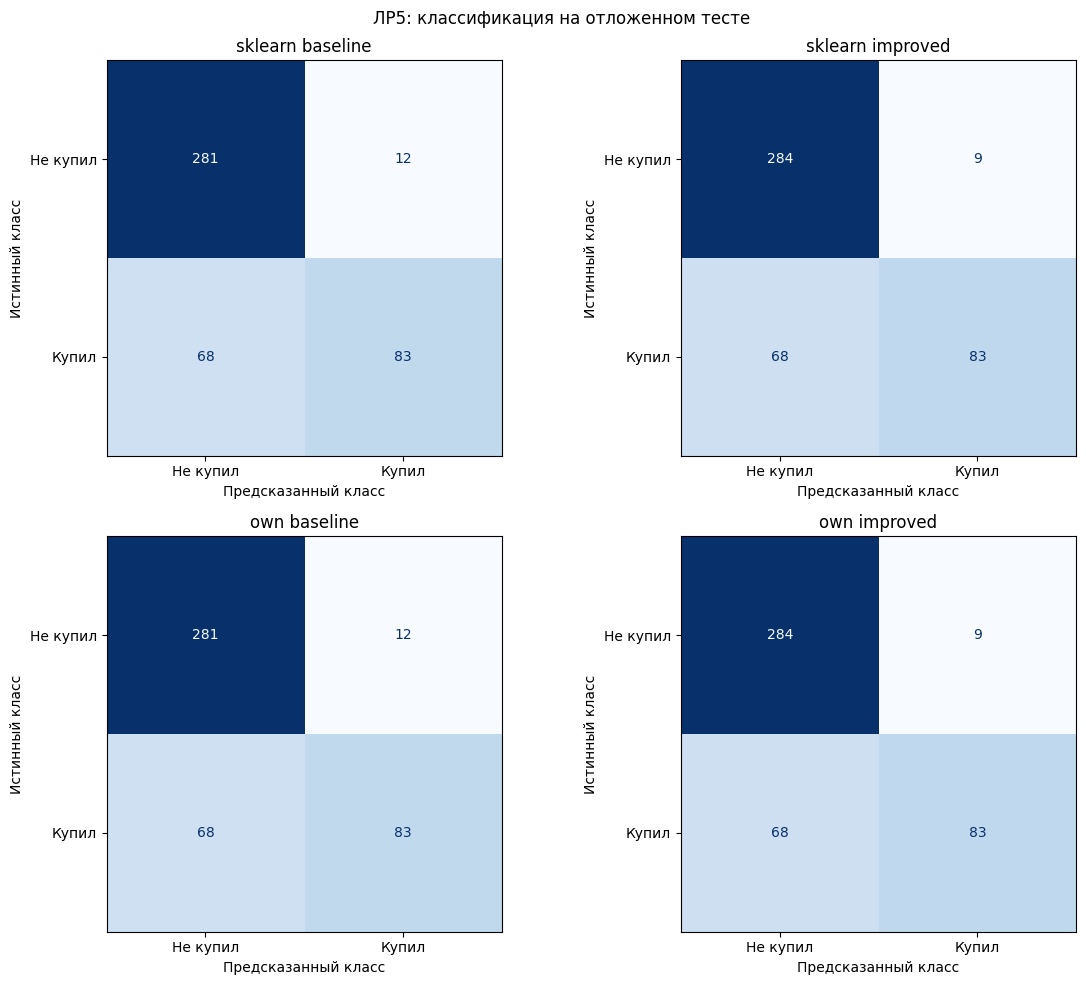

Правильные ответы и ошибки классификации:


,model,tn,fp,fn,tp
0,sklearn baseline,281,12,68,83
1,sklearn improved,284,9,68,83
2,own baseline,281,12,68,83
3,own improved,284,9,68,83


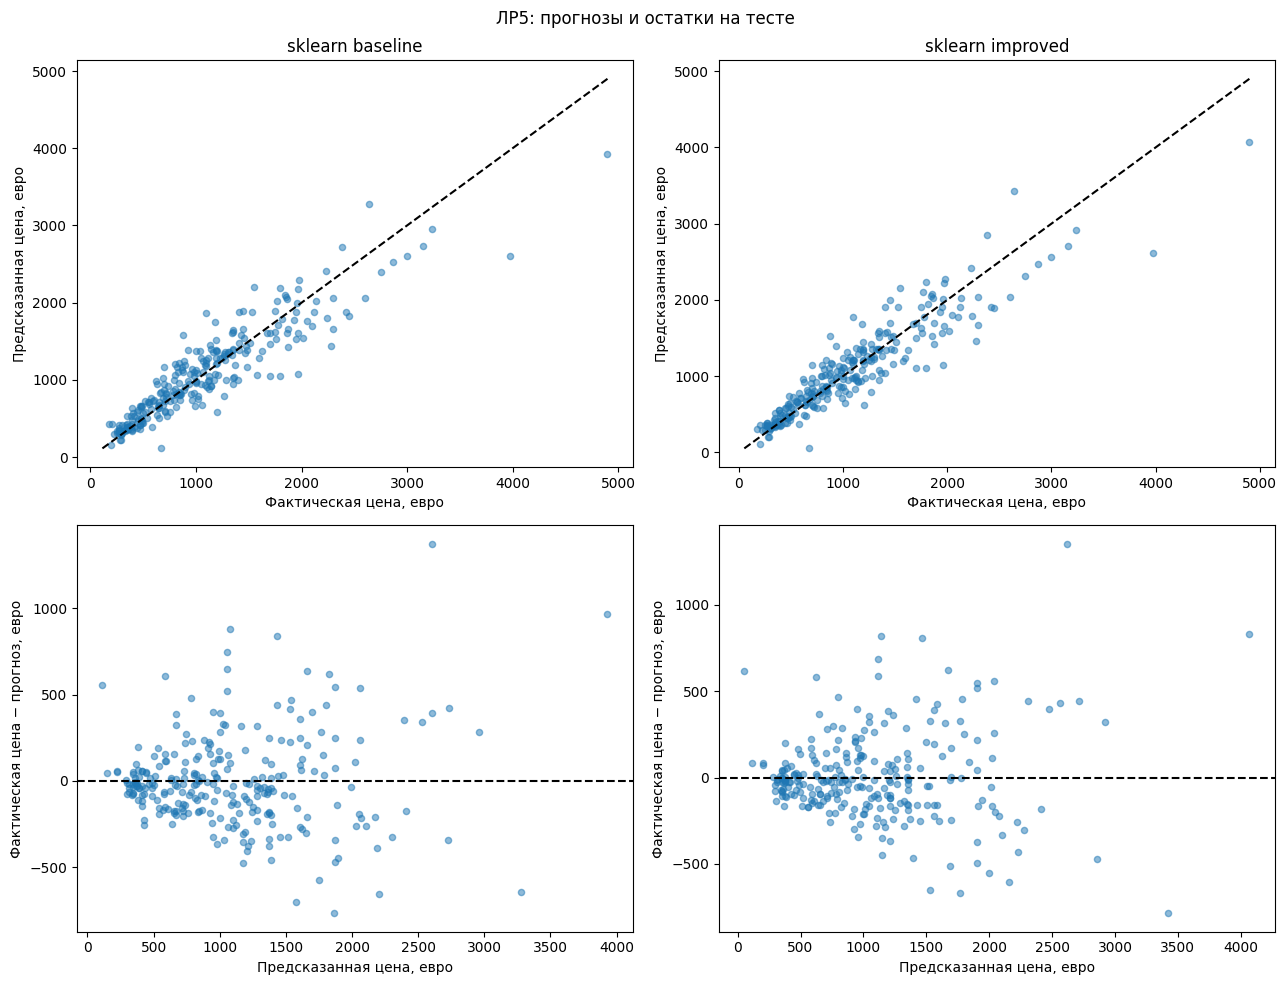

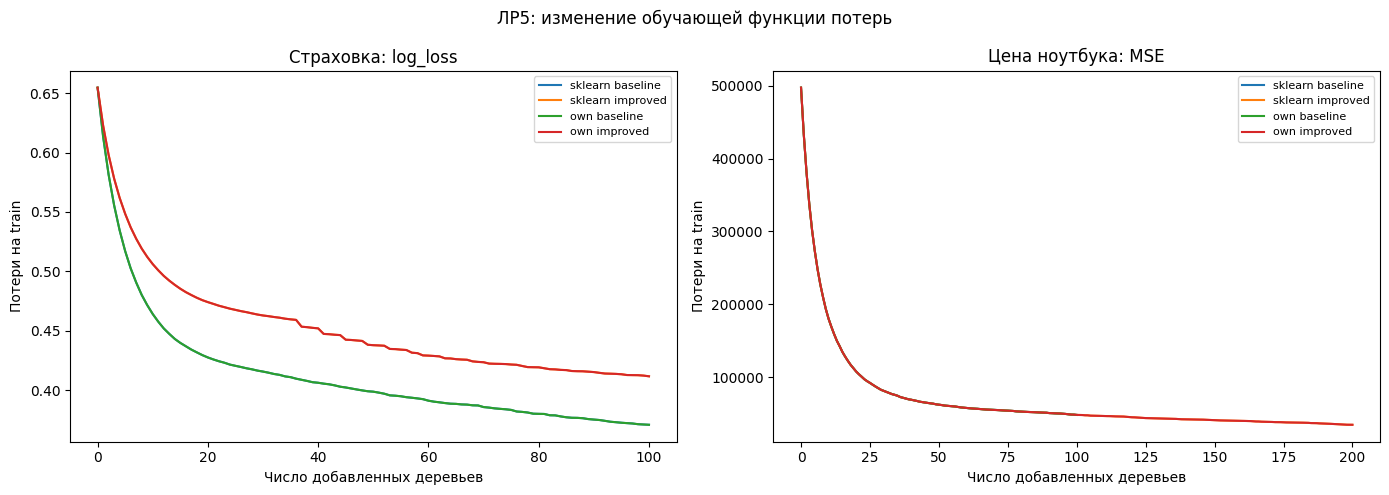

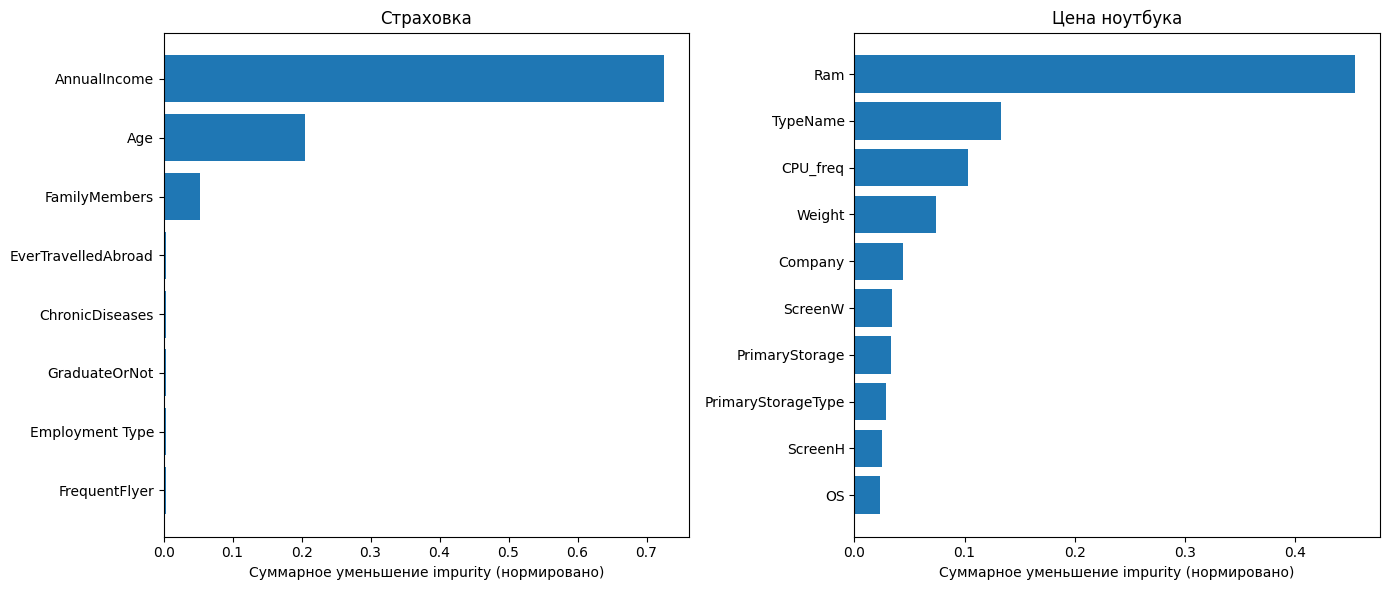

Распределение абсолютных ошибок регрессии, евро:


,model,median_abs_error,p90_abs_error,max_abs_error
0,sklearn baseline,142.60,419.82,1373.95
1,sklearn improved,128.89,437.48,1354.01
2,own baseline,142.60,419.82,1373.95
3,own improved,128.89,437.48,1354.01


Восемь наибольших ошибок выбранного библиотечного регрессора:


,row_position,target,prediction,residual,absolute_error
227,1066,3975.00,2620.99,1354.01,1354.01
119,610,4899.00,4068.51,830.49,830.49
185,904,1962.99,1142.70,820.29,820.29
171,848,2277.00,1467.37,809.63,809.63
66,329,2639.00,3424.00,-785.00,785.00
180,885,1799.00,1112.90,686.10,686.10
155,767,1099.00,1769.36,-670.36,670.36
120,611,879.01,1530.01,-651.00,651.00


Характеристики трёх объектов с наибольшими ошибками:


,row_position,Company,Product,TypeName,Ram,Price_euros
1066,1066,Asus,ROG G701VO,Gaming,64,3975.00
610,610,Lenovo,Thinkpad P51,Notebook,32,4899.00
904,904,Lenovo,ThinkPad T570,Notebook,8,1962.99


Архив результатов подготовлен: lab5_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
"""Разбираем ошибки градиентного бустинга, строим графики и сохраняем результаты ЛР5."""

import importlib.metadata
import zipfile
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, log_loss

figure_dir = results_dir / "lab5_figures"
figure_dir.mkdir(parents=True, exist_ok=True)

# Строки матрицы — истинный класс, столбцы — предсказанный.
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
confusion_rows = []
for ax, name in zip(axes.flat, final_models_cls):
    predicted = final_predictions_cls[name].to_numpy()
    matrix = confusion_matrix(y_test_cls, predicted, labels=[0, 1])
    ConfusionMatrixDisplay(matrix, display_labels=["Не купил", "Купил"]).plot(
        ax=ax, cmap="Blues", colorbar=False,
    )
    ax.set_title(name)
    ax.set_xlabel("Предсказанный класс")
    ax.set_ylabel("Истинный класс")
    tn, fp, fn, tp = matrix.ravel()
    confusion_rows.append({"model": name, "tn": tn, "fp": fp, "fn": fn, "tp": tp})
fig.suptitle("ЛР5: классификация на отложенном тесте")
fig.tight_layout()
fig.savefig(figure_dir / "lab5_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()
confusion_table = pd.DataFrame(confusion_rows)
confusion_table.to_csv(results_dir / "lab5_confusion_counts.csv", index=False)
print("Правильные ответы и ошибки классификации:")
display(confusion_table)

# Показываем исходную модель и вариант, выбранный по CV.
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
target = final_predictions_reg["target"].to_numpy()
for column, name in enumerate(["sklearn baseline", "sklearn improved"]):
    predicted = final_predictions_reg[name].to_numpy()
    low, high = min(target.min(), predicted.min()), max(target.max(), predicted.max())
    axes[0, column].scatter(target, predicted, alpha=0.5, s=20)
    axes[0, column].plot([low, high], [low, high], "k--")
    axes[0, column].set(title=name, xlabel="Фактическая цена, евро",
                        ylabel="Предсказанная цена, евро")
    axes[1, column].scatter(predicted, target - predicted, alpha=0.5, s=20)
    axes[1, column].axhline(0, color="black", linestyle="--")
    axes[1, column].set(xlabel="Предсказанная цена, евро",
                        ylabel="Фактическая цена − прогноз, евро")
fig.suptitle("ЛР5: прогнозы и остатки на тесте")
fig.tight_layout()
fig.savefig(figure_dir / "lab5_regression_errors.png", dpi=150, bbox_inches="tight")
plt.show()

# Графики используют только обучающую выборку. По ним после теста
# не выбираются число итераций или другие параметры.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
loss_rows, tree_rows = [], []
for ax, task, models, X_train, y_train, title in [
    (axes[0], "classification", final_models_cls, X_train_cls, y_train_cls, "Страховка: log_loss"),
    (axes[1], "regression", final_models_reg, X_train_reg, y_train_reg, "Цена ноутбука: MSE"),
]:
    for name, pipeline in models.items():
        model = pipeline.named_steps["model"]
        transformed = pipeline.named_steps["preprocessor"].transform(X_train)
        if task == "classification":
            initial = log_loss(y_train, np.full(len(y_train), y_train.mean()), labels=[0, 1])
            stages = model.staged_predict_proba(transformed)
            losses = [initial] + [log_loss(y_train, values, labels=[0, 1]) for values in stages]
        else:
            initial = mean_squared_error(y_train, np.full(len(y_train), y_train.mean()))
            stages = model.staged_predict(transformed)
            losses = [initial] + [mean_squared_error(y_train, values) for values in stages]
        assert len(losses) == model.n_estimators + 1
        assert np.isfinite(losses).all()
        if hasattr(model, "loss_history_"):
            assert_allclose(losses, model.loss_history_, rtol=1e-9, atol=1e-9)
        ax.plot(np.arange(len(losses)), losses, label=name)
        for iteration, value in enumerate(losses):
            loss_rows.append({"task": task, "model": name,
                              "iteration": iteration, "train_loss": value})
        for number, tree in enumerate(boosting_trees(model)):
            tree_rows.append({"task": task, "model": name, "tree_number": number,
                              "depth": tree.get_depth(), "n_leaves": tree.get_n_leaves()})
    ax.set(title=title, xlabel="Число добавленных деревьев", ylabel="Потери на train")
    ax.legend(fontsize=8)
fig.suptitle("ЛР5: изменение обучающей функции потерь")
fig.tight_layout()
fig.savefig(figure_dir / "lab5_training_loss.png", dpi=150, bbox_inches="tight")
plt.show()
pd.DataFrame(loss_rows).to_csv(results_dir / "lab5_training_loss.csv", index=False)
pd.DataFrame(tree_rows).to_csv(results_dir / "lab5_tree_details.csv", index=False)

# Складываем важности one-hot столбцов каждой исходной категории.
# Это уменьшение impurity на train, а не причинный эффект признака.
importance_rows = []
for task, models in [("classification", final_models_cls), ("regression", final_models_reg)]:
    for name, pipeline in models.items():
        preprocessor = pipeline.named_steps["preprocessor"]
        original_columns = []
        for transformer_name, transformer, columns in preprocessor.transformers_:
            if transformer_name == "numeric":
                original_columns.extend(columns)
            elif transformer_name == "categorical":
                for column, categories in zip(columns, transformer.categories_):
                    original_columns.extend([column] * len(categories))
        values = pipeline.named_steps["model"].feature_importances_
        assert len(values) == len(original_columns)
        grouped = pd.Series(values, index=original_columns).groupby(level=0).sum()
        for feature, value in grouped.items():
            importance_rows.append({"task": task, "model": name,
                                    "feature": feature, "importance": value})
importance_table = pd.DataFrame(importance_rows)
importance_table.to_csv(results_dir / "lab5_feature_importances.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, task, title in zip(axes, ["classification", "regression"], ["Страховка", "Цена ноутбука"]):
    selected = importance_table[
        (importance_table["task"] == task)
        & (importance_table["model"] == "sklearn improved")
    ].nlargest(10, "importance").sort_values("importance")
    ax.barh(selected["feature"], selected["importance"])
    ax.set(title=title, xlabel="Суммарное уменьшение impurity (нормировано)")
fig.tight_layout()
fig.savefig(figure_dir / "lab5_feature_importances.png", dpi=150, bbox_inches="tight")
plt.show()

error_rows = []
for name in final_models_reg:
    predicted = final_predictions_reg[name].to_numpy()
    absolute = np.abs(target - predicted)
    error_rows.append({
        "model": name,
        "median_abs_error": np.median(absolute),
        "p90_abs_error": np.quantile(absolute, 0.9),
        "max_abs_error": absolute.max(),
    })
error_summary = pd.DataFrame(error_rows)
error_summary.to_csv(results_dir / "lab5_regression_error_summary.csv", index=False)
errors = final_predictions_reg[["row_position", "target"]].copy()
errors["prediction"] = final_predictions_reg["sklearn improved"]
errors["residual"] = errors["target"] - errors["prediction"]
errors["absolute_error"] = errors["residual"].abs()
errors = errors.sort_values("absolute_error", ascending=False)
errors.to_csv(results_dir / "lab5_regression_error_details.csv", index=False)
print("Распределение абсолютных ошибок регрессии, евро:")
display(error_summary.round(2))
print("Восемь наибольших ошибок выбранного библиотечного регрессора:")
display(errors.head(8).round(2))
worst_rows = errors.head(3)["row_position"].to_numpy()
worst_objects = laptops.loc[
    worst_rows, ["Company", "Product", "TypeName", "Ram", "Price_euros"],
].copy()
worst_objects.insert(0, "row_position", worst_objects.index)
print("Характеристики трёх объектов с наибольшими ошибками:")
display(worst_objects)
worst_objects.to_csv(results_dir / "lab5_worst_laptops.csv", index=False)

# Сохраняем фактические индексы и части CV, чтобы проверить повторный запуск.
for name, X, group_ids, train_indices, test_indices, folds in [
    ("travel", X_cls, groups_cls, train_idx_cls, test_idx_cls, cv_folds_cls),
    ("laptops", X_reg, groups_reg, train_idx_reg, test_idx_reg, cv_folds_reg),
]:
    split_table = pd.DataFrame({"row_position": np.arange(len(X)), "group": group_ids})
    split_table["split"] = "train"
    split_table.loc[test_indices, "split"] = "test"
    split_table["validation_fold"] = -1
    for fold, (_, validation_positions) in enumerate(folds):
        split_table.loc[train_indices[validation_positions], "validation_fold"] = fold
    split_table.to_csv(results_dir / f"lab5_split_{name}.csv", index=False)

settings = {
    "random_state": RANDOM_STATE,
    "baseline_parameters": BASELINE_BOOSTING,
    "subsample": 1.0,
    "source_sha256": source_hashes,
    "split_fingerprints": expected_protocol,
    "selected_classification": SELECTED_BOOSTING_CLS,
    "selected_regression": SELECTED_BOOSTING_REG,
    "primary_metrics": {"classification": "macro_f1", "regression": "mae"},
    "versions": {"python": sys.version.split()[0], **{
        name: importlib.metadata.version(name)
        for name in ["numpy", "pandas", "scikit-learn", "matplotlib", "seaborn"]
    }},
    "timing_note": "Один запуск, с предобработкой; predict_proba измерено отдельно.",
}
(results_dir / "lab5_settings.json").write_text(
    json.dumps(settings, ensure_ascii=False, indent=2), encoding="utf-8",
)
archive_path = Path("/content/lab5_artifacts.zip")
with zipfile.ZipFile(archive_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(results_dir.rglob("lab5_*")):
        if path.is_file():
            archive.write(path, arcname=str(path.relative_to(results_dir)))
print("Архив результатов подготовлен:", archive_path.name)
files.download(str(archive_path))

### Что показывают ошибки

У библиотечного классификатора число ложных срабатываний уменьшилось
с 12 до 9, а число найденных покупателей осталось равным 83 из 151.
Это объясняет рост precision при неизменном recall. Матрицы ошибок
собственных моделей совпали с соответствующими библиотечными:
у настроенного варианта TN=284, FP=9, FN=68, TP=83.

У библиотечного регрессора медианная абсолютная ошибка уменьшилась
с 142.60 до 128.89 евро. Однако 90-й процентиль вырос
с 419.82 до 437.48 евро. Максимальная ошибка немного уменьшилась
с 1373.95 до 1354.01 евро. Снижение MAE и RMSE поэтому не означает
улучшения каждой части распределения ошибок.

Крупнейший промах выбранной модели — Asus ROG G701VO с 64 ГБ RAM:
фактическая цена 3975 евро, прогноз 2620.99 евро.
Далее следуют Lenovo Thinkpad P51 и ThinkPad T570.
Эти примеры показывают сохраняющуюся недооценку отдельных конфигураций,
но не доказывают одну общую причину ошибок.

Кривые обучения отражают минимизацию log_loss и MSE на train.
Они не являются кривыми качества на независимой выборке и не служат
основанием для изменения числа деревьев после просмотра теста.

## Итоговые выводы

В классификации я уменьшил глубину деревьев с 3 до 2 по результатам CV.
На тесте macro-F1 вырос с 0.7751 до 0.7819 у обеих реализаций.
Precision составил 0.9022, recall — 0.5497. Число найденных покупателей
не изменилось, уменьшилось число ложных срабатываний.

В регрессии выбрано 200 деревьев вместо 100 при learning_rate=0.1.
Тестовая MAE снизилась с 192.96 до 182.12 евро у sklearn
и с 192.65 до 181.99 евро у реализации на NumPy. RMSE также снизилась,
но 90-й процентиль абсолютной ошибки вырос. Улучшение среднего
качества не означает, что каждый прогноз стал точнее.

В собственной реализации проверены начальный прогноз, отрицательный
градиент и последовательное добавление деревьев. Для log_loss
значения листьев уточняются шагом Ньютона. Внутренние деревья
реализованы на NumPy; проверки первых шагов и воспроизводимости прошли.

Настройки выбраны по групповой CV до оценки на тесте. Сравнение
с остальными алгоритмами приведено в [итоговом ноутбуке](lab6_summary.ipynb).